In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


In [2]:
tabular_path = 'data/raw/tabular/patient_records.csv'
images_dir = 'data/raw/images/'
print('Tabular Path:', tabular_path)
print('Images Dir  :', images_dir)


Tabular Path: data/raw/tabular/patient_records.csv
Images Dir  : data/raw/images/


In [3]:
df = pd.read_csv(tabular_path)
print('Number of clinical encounters:', len(df))
print('Unique patients (subject_id) :', df['subject_id'].nunique())
df.head()


Number of clinical encounters: 229
Unique patients (subject_id) : 180


In [4]:
stable_files = df[df['outcome'] == 0]['image_path'].tolist()
critical_files = df[df['outcome'] == 1]['image_path'].tolist()

print('Number of stable patient images   :', len(stable_files))
print('Number of critical patient images :', len(critical_files))


Number of stable patient images   : 170
Number of critical patient images : 59


In [5]:
stable_labels = [0] * len(stable_files)
critical_labels = [1] * len(critical_files)

print(stable_labels[0:5])
print(critical_labels[0:5])


[0, 0, 0, 0, 0]
[1, 1, 1, 1, 1]


In [6]:
print(len(stable_labels))
print(len(critical_labels))


170
59


In [7]:
labels = df['outcome'].tolist()
print('Total labels:', len(labels))


Total labels: 229


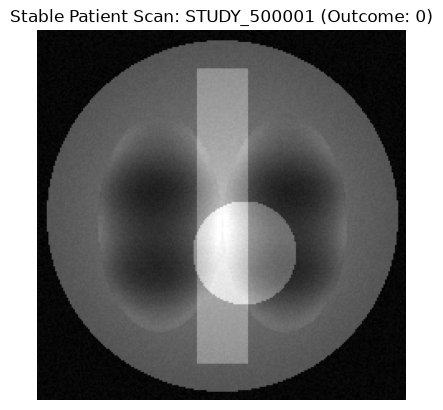

In [8]:
img_stable = mpimg.imread(stable_files[0])
plt.imshow(img_stable, cmap='gray')
plt.title(f"Stable Patient Scan: {df[df['outcome']==0].iloc[0]['study_id']} (Outcome: 0)")
plt.axis('off')
plt.show()


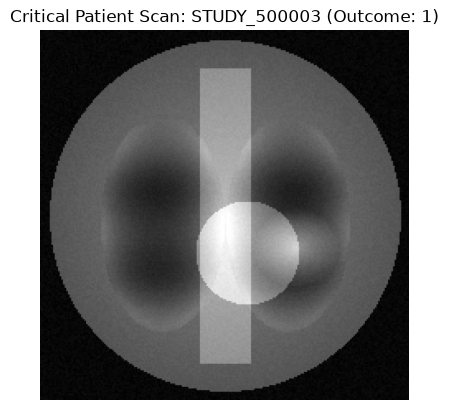

In [9]:
img_crit = mpimg.imread(critical_files[0])
plt.imshow(img_crit, cmap='gray')
plt.title(f"Critical Patient Scan: {df[df['outcome']==1].iloc[0]['study_id']} (Outcome: 1)")
plt.axis('off')
plt.show()


In [10]:
image_data = []

for idx, row in df.iterrows():
    img_path = row['image_path']
    image = Image.open(img_path)
    image = image.resize((128, 128))
    image = image.convert('RGB')
    image = np.array(image)
    image_data.append(image)


In [11]:
type(image_data)


In [12]:
len(image_data)


In [13]:
image_data[0]


In [14]:
type(image_data[0])


In [15]:
image_data[0].shape


In [16]:
numerical_features = [
    'age', 'heart_rate', 'sbp', 'dbp', 'resp_rate',
    'spo2', 'temp', 'wbc', 'creatinine', 'glucose',
    'hemoglobin', 'platelets'
]
tabular_data = df[numerical_features].values.astype(np.float32)


In [17]:
type(tabular_data)


In [18]:
tabular_data.shape


In [19]:
tabular_data[0]


In [20]:
X_img = np.array(image_data)
X_tab = np.array(tabular_data)
Y = np.array(labels)


In [21]:
type(X_img)


In [22]:
type(X_tab)


In [23]:
type(Y)


In [24]:
print('X_img shape:', X_img.shape)
print('X_tab shape:', X_tab.shape)
print('Y shape    :', Y.shape)


X_img shape: (229, 128, 128, 3)
X_tab shape: (229, 12)
Y shape    : (229,)


In [25]:
print(Y)


[0 0 1 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 1
 0 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 1 1
 0 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 1 0
 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0
 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 1 0 0 0
 1 0 0 0 1 0 0]


In [26]:
from sklearn.model_selection import train_test_split


In [27]:
X_img_train, X_img_test, X_tab_train, X_tab_test, Y_train, Y_test = train_test_split(
    X_img, X_tab, Y, test_size=0.2, random_state=42, stratify=Y
)


In [28]:
print('Images  :', X_img.shape, X_img_train.shape, X_img_test.shape)
print('Tabular :', X_tab.shape, X_tab_train.shape, X_tab_test.shape)


Images  : (229, 128, 128, 3) (183, 128, 128, 3) (46, 128, 128, 3)
Tabular : (229, 12) (183, 12) (46, 12)


In [29]:
# 1. Image Scaling to [0, 1]
X_img_train_scaled = X_img_train / 255.0
X_img_test_scaled = X_img_test / 255.0

# 2. Tabular Standard Scaling (fit on train)
tab_mean = X_tab_train.mean(axis=0)
tab_std = X_tab_train.std(axis=0)
tab_std[tab_std < 1e-6] = 1.0

X_tab_train_scaled = (X_tab_train - tab_mean) / tab_std
X_tab_test_scaled = (X_tab_test - tab_mean) / tab_std


In [30]:
X_img_train[0]


In [31]:
X_img_train_scaled[0]


In [32]:
X_tab_train_scaled[0]


In [33]:
class MultimodalClinicalNet(nn.Module):
    def __init__(self, num_tabular_features=12):
        super().__init__()
        # CNN Vision Stream for Chest X-Ray
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Dense Stream for Tabular EHR
        self.tab_fc1 = nn.Linear(num_tabular_features, 64)
        self.tab_bn1 = nn.BatchNorm1d(64)
        self.tab_fc2 = nn.Linear(64, 64)
        self.tab_bn2 = nn.BatchNorm1d(64)

        # Multimodal Fusion & Classification Head
        self.fuse_fc1 = nn.Linear(128 + 64, 128)
        self.fuse_bn1 = nn.BatchNorm1d(128)
        self.dropout1 = nn.Dropout(0.3)
        self.fuse_fc2 = nn.Linear(128, 64)
        self.dropout2 = nn.Dropout(0.2)
        self.out = nn.Linear(64, 2)

    def forward(self, img, tab):
        # Image stream [B, 3, 128, 128]
        x_img = self.pool(F.relu(self.bn1(self.conv1(img))))
        x_img = self.pool(F.relu(self.bn2(self.conv2(x_img))))
        x_img = self.pool(F.relu(self.bn3(self.conv3(x_img))))
        x_img = self.global_pool(x_img).flatten(1)  # [B, 128]

        # Tabular stream [B, 12]
        x_tab = F.relu(self.tab_bn1(self.tab_fc1(tab)))
        x_tab = F.relu(self.tab_bn2(self.tab_fc2(x_tab)))  # [B, 64]

        # Fusion & Prediction
        fused = torch.cat([x_img, x_tab], dim=-1)  # [B, 192]
        h = self.dropout1(F.relu(self.fuse_bn1(self.fuse_fc1(fused))))
        h = self.dropout2(F.relu(self.fuse_fc2(h)))
        logits = self.out(h)
        return logits


In [34]:
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu'))
model = MultimodalClinicalNet(num_tabular_features=12).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Multimodal-Clinical-Fusion-Net initialized!')
print(f'Device: {device}')
print(f'Total Trainable Parameters: {total_params:,}')
print(model)


Multimodal-Clinical-Fusion-Net initialized!
Device: mps
Total Trainable Parameters: 132,290
MultimodalClinicalNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (tab_fc1): Linear(in_features=12, out_features=64, bias=True)
  (tab_bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (tab_fc2): Linear(in_features=64, out_featu

In [35]:
# Compile the neural network
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()


In [36]:
# Convert numpy arrays to PyTorch Tensors & DataLoaders
t_img_train = torch.tensor(X_img_train_scaled.transpose(0, 3, 1, 2), dtype=torch.float32)
t_tab_train = torch.tensor(X_tab_train_scaled, dtype=torch.float32)
t_y_train = torch.tensor(Y_train, dtype=torch.long)

t_img_test = torch.tensor(X_img_test_scaled.transpose(0, 3, 1, 2), dtype=torch.float32)
t_tab_test = torch.tensor(X_tab_test_scaled, dtype=torch.float32)
t_y_test = torch.tensor(Y_test, dtype=torch.long)

from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(t_img_train, t_tab_train, t_y_train)
test_dataset = TensorDataset(t_img_test, t_tab_test, t_y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [37]:
# Training (model.fit)
epochs = 20
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, epochs + 1):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for b_img, b_tab, b_y in train_loader:
        b_img, b_tab, b_y = b_img.to(device), b_tab.to(device), b_y.to(device)
        optimizer.zero_grad()
        logits = model(b_img, b_tab)
        loss = criterion(logits, b_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(b_y)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == b_y).sum().item()
        total += len(b_y)

    train_loss = total_loss / total
    train_acc = correct / total

    # Evaluate on test split
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for b_img, b_tab, b_y in test_loader:
            b_img, b_tab, b_y = b_img.to(device), b_tab.to(device), b_y.to(device)
            logits = model(b_img, b_tab)
            loss = criterion(logits, b_y)
            val_loss += loss.item() * len(b_y)
            preds = torch.argmax(logits, dim=1)
            val_correct += (preds == b_y).sum().item()
            val_total += len(b_y)

    test_loss = val_loss / val_total
    test_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)

    print(f'Epoch [{epoch:02d}/{epochs:02d}] - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - val_loss: {test_loss:.4f} - val_accuracy: {test_acc:.4f}')


Epoch [01/20] - loss: 0.5742 - accuracy: 0.7923 - val_loss: 0.5968 - val_accuracy: 0.7391
Epoch [02/20] - loss: 0.3014 - accuracy: 0.9781 - val_loss: 0.4199 - val_accuracy: 0.7391
Epoch [03/20] - loss: 0.1353 - accuracy: 1.0000 - val_loss: 0.3226 - val_accuracy: 0.7609
Epoch [04/20] - loss: 0.0672 - accuracy: 0.9945 - val_loss: 0.3591 - val_accuracy: 0.8261
Epoch [05/20] - loss: 0.0284 - accuracy: 1.0000 - val_loss: 0.3546 - val_accuracy: 0.8696
Epoch [06/20] - loss: 0.0289 - accuracy: 0.9945 - val_loss: 0.2726 - val_accuracy: 0.9130
Epoch [07/20] - loss: 0.0081 - accuracy: 1.0000 - val_loss: 0.1578 - val_accuracy: 0.9348
Epoch [08/20] - loss: 0.0064 - accuracy: 1.0000 - val_loss: 0.0703 - val_accuracy: 0.9783
Epoch [09/20] - loss: 0.0047 - accuracy: 1.0000 - val_loss: 0.0129 - val_accuracy: 1.0000
Epoch [10/20] - loss: 0.0037 - accuracy: 1.0000 - val_loss: 0.0047 - val_accuracy: 1.0000
Epoch [11/20] - loss: 0.0104 - accuracy: 1.0000 - val_loss: 0.0024 - val_accuracy: 1.0000
Epoch [12/

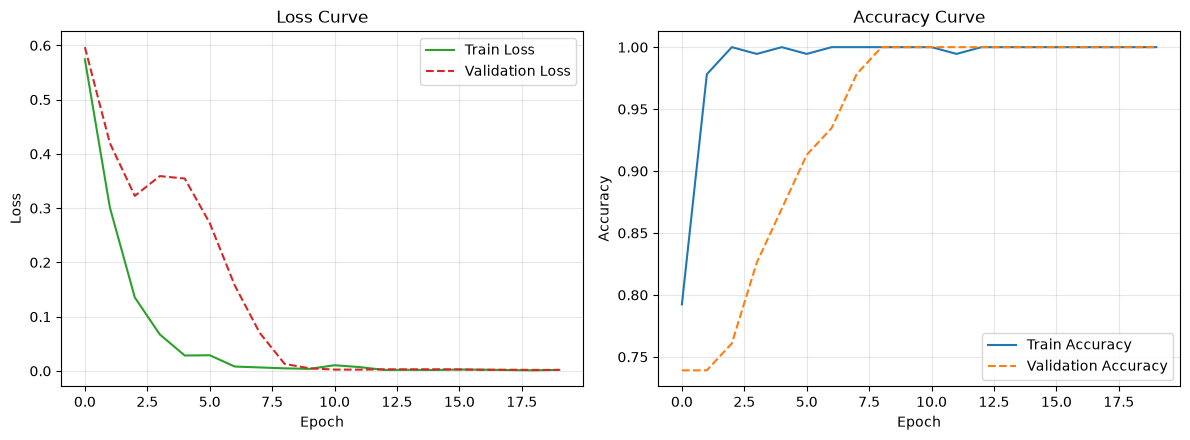

In [38]:
# Plot Training & Validation Loss and Accuracy Curves
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', color='#2ca02c')
plt.plot(history['test_loss'], label='Validation Loss', color='#d62728', linestyle='--')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy', color='#1f77b4')
plt.plot(history['test_acc'], label='Validation Accuracy', color='#ff7f0e', linestyle='--')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [39]:
model.eval()
test_loss, test_correct, test_total = 0.0, 0, 0
with torch.no_grad():
    for b_img, b_tab, b_y in test_loader:
        b_img, b_tab, b_y = b_img.to(device), b_tab.to(device), b_y.to(device)
        logits = model(b_img, b_tab)
        loss = criterion(logits, b_y)
        test_loss += loss.item() * len(b_y)
        preds = torch.argmax(logits, dim=1)
        test_correct += (preds == b_y).sum().item()
        test_total += len(b_y)

loss = test_loss / test_total
accuracy = test_correct / test_total

print('Test Loss =', loss)
print('Test Accuracy =', accuracy)


Test Loss = 0.0017236610874533653
Test Accuracy = 1.0


Input Image Path: data/raw/images/STUDY_500003.png
Prediction probabilities [Stable, Critical]: [0.00239183 0.9976082 ]
Predicted label: 1
ALERT: The patient is at HIGH CLINICAL RISK / CRITICAL (Pulmonary Infiltrate / Sepsis detected)!


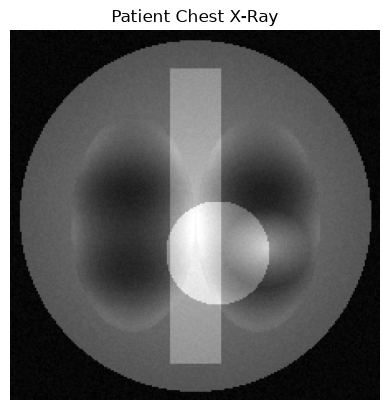

In [40]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Sample Chest X-ray image for testing
input_image_path = df[df['outcome'] == 1].iloc[0]['image_path']
print('Input Image Path:', input_image_path)

input_image = Image.open(input_image_path)
plt.imshow(input_image, cmap='gray')
plt.title('Patient Chest X-Ray')
plt.axis('off')
plt.show()

# Image Preprocessing
input_image = input_image.convert('RGB')
input_image = input_image.resize((128, 128))
input_image = np.array(input_image).astype('float32') / 255.0
input_img_tensor = torch.tensor(input_image.transpose(2, 0, 1), dtype=torch.float32).unsqueeze(0).to(device)

# Tabular Preprocessing
sample_patient_record = df[df['outcome'] == 1].iloc[0]
raw_tabular_input = sample_patient_record[numerical_features].values.astype(np.float32)
scaled_tabular_input = (raw_tabular_input - tab_mean) / tab_std
input_tab_tensor = torch.tensor(scaled_tabular_input, dtype=torch.float32).unsqueeze(0).to(device)

# Prediction
model.eval()
with torch.no_grad():
    logits = model(input_img_tensor, input_tab_tensor)
    input_prediction = F.softmax(logits, dim=1).cpu().numpy()[0]

print('Prediction probabilities [Stable, Critical]:', input_prediction)

input_pred_label = np.argmax(input_prediction)
print('Predicted label:', input_pred_label)

if input_pred_label == 1:
    print('ALERT: The patient is at HIGH CLINICAL RISK / CRITICAL (Pulmonary Infiltrate / Sepsis detected)!')
else:
    print('The patient is STABLE (Normal vitals and clear lung fields).')


In [41]:
# PyTorch format
torch.save(model.state_dict(), 'Multimodal-Clinical-Fusion-Net_model.pt')

# PKL format
import pickle

with open('Multimodal-Clinical-Fusion-Net_model.pkl', 'wb') as file:
    pickle.dump({
        'model_state_dict': model.state_dict(),
        'tab_mean': tab_mean,
        'tab_std': tab_std,
        'numerical_features': numerical_features
    }, file)

print('Both models saved successfully!')


Both models saved successfully!
